This notebook reproduces Fig. 13.

We compare the $(\alpha,\beta)$-hypergeometric pulses with two numerical optimal-control techniques, CRAB and GRAPE, as implemented in `qutip-qtrl`, for the Landau-Zener problem $\hat{H}=z(t)\hat{\sigma}_z+x\hat{\sigma}_x$. Both algorithms optimize a piecewise-constant pulse with `n_ts` time slices and amplitude $|z(t)|\leq 10\,x$, to transfer the state $|0\rangle$ into $|1\rangle$ (the eigenstates of $\hat{\sigma}_z$) for a fixed total time $t_\mathrm{f}$. CRAB uses a Fourier basis with 6 coefficients modulating a linear guess pulse, while GRAPE starts from a linear pulse. As a representative example of the hypergeometric pulses, we use the geometric fast-QUAD, $(\alpha,\beta)=(2,2)$, with boundary conditions $z(t=0)=-z(t=t_\mathrm{f})=-10\,x$.

Note that CRAB uses random initial coefficients, so the results may slightly change between different runs.

Here, we use physical units: the tunneling rate is $x=1\;\mu$eV, energies are given in $\mu$eV and times in ns. The pulses (optimized without any filter) are filtered with a third-order Butterworth filter with cut-off frequency $f_c$ (see `Fig07-filtered_pulses.ipynb`), and the fidelity $\mathcal{F}=|\langle 1|\Psi(t_\mathrm{f})\rangle|^2$ is computed for the coherent evolution with the filtered pulse. The same initial ($|0\rangle$) and target ($|1\rangle$) states are used for all the protocols.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import qutip as qt
import qutip_qtrl.pulseoptim as cpo
from parameterrun import parameterrun
from scipy.constants import e, hbar

from HQUAD_lib.physics_utils import filter_pulse
from HQUAD_lib.plotting_utils import add_labels
from HQUAD_lib.QUAD_utils import compute_x_quad

In [2]:
hbar_ueV_ns = hbar / e * 1e6 * 1e9  # hbar in ueV * ns


def hamiltonian(z: float, x: float) -> np.ndarray:
    return np.array([[z, x], [x, -z]]) / hbar_ueV_ns


order = 3  # Order of the Butterworth filter
x = 1  # Tunneling rate (ueV)
n_ts = 1000  # Time slices
amp_lbound, amp_ubound = -10.0, 10.0  # (ueV)

n_tf = 60  # Increase to enhance the resolution (500 values in the manuscript)
tf_list = np.linspace(0.1, 20, n_tf)  # (ns)
fc_list = [4, 1, 0.5]  # (GHz)

psi0 = qt.basis(2, 0)
psit = qt.basis(2, 1)

H_d = qt.Qobj(hamiltonian(0, x))
H_c = qt.Qobj(hamiltonian(1, 0))

CRAB_color = "lightskyblue"
GRAPE_color = "mediumpurple"
geometric_color = "indigo"

In [3]:
def solve_CRAB(tf: float, H_d: qt.Qobj, H_c: qt.Qobj) -> np.ndarray:
    res = cpo.opt_pulse_crab(
        drift=H_d,
        ctrls=[H_c],
        initial=psi0,
        target=psit,
        num_tslots=n_ts,
        evo_time=tf,
        amp_lbound=amp_lbound,
        amp_ubound=amp_ubound,
        fid_err_targ=1e-20,
        max_iter=500,
        num_coeffs=6,
        guess_pulse_type="LIN",
        init_coeff_scaling=amp_ubound,
        prop_type="DIAG",
        dyn_type="UNIT",
        fid_type="UNIT",
        fid_params={"phase_option": "PSU"},
        log_level=0,
        gen_stats=False,
    )
    return res.final_amps[:, 0]


def solve_GRAPE(tf: float, H_d: qt.Qobj, H_c: qt.Qobj) -> np.ndarray:
    res = cpo.optimize_pulse(
        drift=H_d,
        ctrls=[H_c],
        initial=psi0,
        target=psit,
        num_tslots=n_ts,
        evo_time=tf,
        fid_err_targ=1e-20,
        max_iter=1000,
        max_wall_time=1000,
        amp_lbound=amp_lbound,
        amp_ubound=amp_ubound,
        init_pulse_type="LIN",
        pulse_scaling=amp_ubound,
        alg="GRAPE",
        prop_type="DIAG",
        dyn_type="UNIT",
        fid_type="UNIT",
        fid_params={"phase_option": "PSU"},
        log_level=0,
    )
    return res.final_amps[:, 0]

# Pulses

In [4]:
pulses_CRAB = np.asarray(parameterrun(solve_CRAB, "tf", tf_list, H_d=H_d, H_c=H_c))
pulses_GRAPE = np.asarray(parameterrun(solve_GRAPE, "tf", tf_list, H_d=H_d, H_c=H_c))

solve_CRAB: [['tf']]:   0%|          | 0/60 [00:00<?, ?it/s]

solve_GRAPE: [['tf']]:   0%|          | 0/60 [00:00<?, ?it/s]

In [5]:
# Geometric pulse
zs = np.linspace(
    amp_lbound, amp_ubound, 2**15 + 1
)  # 2 ** 20 + 1 points in the manuscript
partial_hamiltonian = np.array([np.array([[1, 0], [0, -1]]) for _ in range(len(zs))])

hypermatrix = np.array([hamiltonian(z, x) for z in zs])
eigvalues, eigmodes = np.linalg.eigh(hypermatrix)

alpha = 2
beta = 2

s, pulse_hyper = compute_x_quad(
    eigvalues,
    eigmodes,
    zs,
    partial_hamiltonian,
    adiabatic_state=0,
    alpha=alpha,
    beta=beta,
    n_s=2**14 + 1,
)

# Dynamics

In [6]:
def compute_fidelity(pulse: np.ndarray, tf: float, fc: float) -> float:
    time = np.linspace(0, tf, len(pulse), endpoint=False)
    pulse_filtered = filter_pulse(pulse, time, order=order, fc=fc)

    # Only the final state is stored, to speed up the dynamics
    H_t = [H_d, [H_c, qt.coefficient(pulse_filtered, tlist=time)]]
    options = {"store_states": False, "store_final_state": True, "nsteps": 10**7}
    psi_T = qt.sesolve(H_t, psi0, [0, time[-1]], options=options).final_state
    return np.abs(psit.overlap(psi_T)) ** 2


fidelities_CRAB = np.asarray(
    parameterrun(
        compute_fidelity, [["pulse", "tf"], ["fc"]], [[pulses_CRAB, tf_list], [fc_list]]
    )
)
fidelities_GRAPE = np.asarray(
    parameterrun(
        compute_fidelity,
        [["pulse", "tf"], ["fc"]],
        [[pulses_GRAPE, tf_list], [fc_list]],
    )
)
fidelities_geometric = np.asarray(
    parameterrun(compute_fidelity, ["tf", "fc"], [tf_list, fc_list], pulse=pulse_hyper)
)

fidelities_CRAB = fidelities_CRAB.reshape((len(tf_list), len(fc_list)))
fidelities_GRAPE = fidelities_GRAPE.reshape((len(tf_list), len(fc_list)))
fidelities_geometric = fidelities_geometric.reshape((len(tf_list), len(fc_list)))

compute_fidelity: [['pulse', 'tf'], ['fc(...)]:   0%|          | 0/180 [00:00<?, ?it/s]

compute_fidelity: [['pulse', 'tf'], ['fc(...)]:   0%|          | 0/180 [00:00<?, ?it/s]

compute_fidelity: [['tf'], ['fc']]:   0%|          | 0/180 [00:00<?, ?it/s]

# Plot

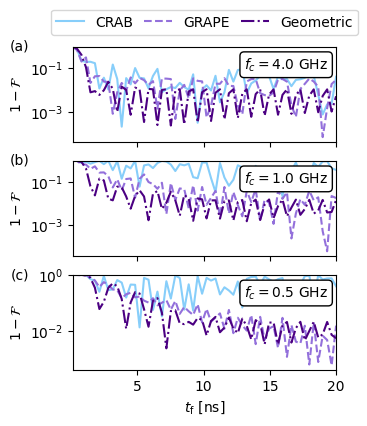

In [7]:
fig, axs = plt.subplots(len(fc_list), 1, sharex=True, figsize=(3.4, 4.2))

for i in range(len(fc_list)):
    axs[i].plot(tf_list, 1 - fidelities_CRAB[:, i], label="CRAB", color=CRAB_color)
    axs[i].plot(
        tf_list, 1 - fidelities_GRAPE[:, i], label="GRAPE", color=GRAPE_color, ls="--"
    )
    axs[i].plot(
        tf_list,
        1 - fidelities_geometric[:, i],
        label="Geometric",
        color=geometric_color,
        ls="-.",
    )

    axs[i].set_yscale("log")
    axs[i].set_ylabel(r"$1 - \mathcal{F}$")

    axs[i].text(
        0.97,
        0.9,
        rf"$f_c = {fc_list[i]:.1f}$ GHz",
        transform=axs[i].transAxes,
        va="top",
        ha="right",
        bbox={"boxstyle": "round", "ec": "k", "fc": "w", "alpha": 1},
    )

    axs[i].set_ylim(None, 1)

axs[0].legend(
    ncols=3,
    frameon=True,
    loc="lower center",
    bbox_to_anchor=(0.5, 1.05),
    labelspacing=0.5,
    columnspacing=0.8,
)

axs[-1].set_xlim(min(tf_list), max(tf_list))
axs[-1].set_xlabel(r"$t_\mathrm{f}$ [ns]")

add_labels(axs, [-0.2, 1.0])